# How much ground does each student get?

The question: how much land (school grounds) does each student get, across the government schools of inner Sydney and
Parramatta? NSW government schools in inner Sydney and Parramatta publish a code, a name, a location and 22 years of headcounts.
They do not publish the school grounds. Without a shape there is no area, and without an area there is no "per square
metre". The shapes in `data/geometry/` were made in [Plotlay](https://www.getplotlay.com): NSW Cadastre lots picked and
merged for each school, and the few schools without a lot of their own drawn over the NSW aerial imagery. Each shape
carries its school code, so it joins to the department's tables.

This notebook reads only the files in `../data`, recomputes every number it shows, and runs top to bottom in under a
minute.

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DATA = '../data'
pd.set_option('display.width', 140)
INK, RED, MUTED, FILM = '#1d4f91', '#cf3b26', '#5b6573', '#f2efe6'
BINS = [0, 10, 15, 25, 50, np.inf]
BIN_LABELS = ['under 10 m²', '10 to 15', '15 to 25', '25 to 50', '50 m² or more']
BIN_COLOURS = ['#6b1a10', '#b8321f', '#e0714a', '#f0aa82', '#f8dcc6']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

School data: NSW Department of Education (Centre for Education Statistics and Evaluation), data.nsw.gov.au, under
Creative Commons Attribution (CC BY). Cadastre and aerial imagery: © State of New South Wales (Spatial Services), CC BY
3.0 AU. The outlines were made in Plotlay from NSW Cadastre lots and drawn over NSW Imagery; there is nothing from
OpenStreetMap in this repository. The full credits are in `NOTICE`.

## Load the tables

One row per school (`schools.csv`) and two long tables with a row per school and year. Headcounts of 5 or fewer are
published as `SP` (suppressed): they stay blank and are never filled in or worked out from totals. None of the 81
schools here has a suppressed headcount.

In [2]:
schools = pd.read_csv(f'{DATA}/schools/schools.csv')
enrol = pd.read_csv(f'{DATA}/schools/enrolments_long.csv')
att = pd.read_csv(f'{DATA}/schools/attendance_long.csv')
assert schools.school_key.is_unique
assert not enrol.duplicated(['school_key', 'year']).any()
assert (enrol.students > 0).all(), 'blanks stay blank: no zeros stand in for suppressed values'
print(len(schools), 'schools;', len(enrol), 'school-years of headcount;', len(att), 'of attendance')
schools[['school_key', 'school_name', 'level', 'opened', 'shape_source', 'outline_check']].head()

81 schools; 1686 school-years of headcount; 946 of attendance


,school_key,school_name,level,opened,shape_source,outline_check
0,8913,Inner Sydney High School,Secondary School,2020-01-28,NSW Cadastre lots,ok
1,8135,Parramatta High School,Secondary School,1913-01-01,NSW Cadastre lots,ok
2,8892,Arthur Phillip High School,Secondary School,1958-01-01,NSW Cadastre lots,ok
3,7442,Woollahra Public School,Primary School,1878-03-01,NSW Cadastre lots,ok
4,3305,Ultimo Public School,Primary School,1858-01-10,NSW Cadastre lots,ok


## Load the shapes

The GeoJSON is the Plotlay export: WGS 84 longitude and latitude, a `key` (the school code) on every shape, `area_m2`,
and `source` saying how the outline was made. The areas are checked here in a metre grid (GDA2020 MGA zone 56,
EPSG:7856), not in degrees.

In [3]:
shapes = gpd.read_file(f'{DATA}/geometry/schools.geojson')
shapes['school_key'] = shapes['key'].astype(int)
shapes['grounds_m2'] = shapes['area_m2']                 # the area Plotlay exported
shapes['area_7856'] = shapes.to_crs(7856).area          # the same outlines measured here
assert shapes.school_key.is_unique
diff = (shapes.area_7856 - shapes.grounds_m2).abs() / shapes.area_7856
print(f'{len(shapes)} shapes; largest difference between the Plotlay area and EPSG:7856: {diff.max():.2%}')
shapes.source.value_counts()

81 shapes; largest difference between the Plotlay area and EPSG:7856: 0.11%


source
NSW Cadastre (Spatial Services)    75
Drawn over NSW aerial imagery       6
Name: count, dtype: int64

## The join

The key is the whole trick: one shared column. Every school in the tables should have exactly one shape.

In [4]:
g = shapes[['school_key', 'grounds_m2', 'source', 'geometry']].merge(schools.drop(columns=['grounds_m2']), on='school_key', how='right', validate='one_to_one', indicator=True)
print(g['_merge'].value_counts().to_dict())
g = gpd.GeoDataFrame(g.drop(columns='_merge'), geometry='geometry', crs=4326)
long = enrol.merge(g[['school_key', 'school_name', 'level', 'grounds_m2', 'compare']], on='school_key', validate='many_to_one', suffixes=('_t', ''))
long['m2_per_student'] = long.grounds_m2 / long.students

{'both': 81, 'left_only': 0, 'right_only': 0}


## Ground per student, 2025

Grounds are the land a school sits on, buildings included. They are not floor space and not playground area, and
parks or sports grounds next door are not counted. Schools are compared only when they are mainstream (not schools for
specific purposes), their outline passed the check on the aerial imagery, and they are not one of the two vertical
schools (`compare` is true): see `data/schools/outline_checklist.csv` and the `vertical` column. Students are the
department's 2025 headcount.

In [5]:
y25 = long[long.year == 2025].copy()
cmp25 = y25[y25['compare']]
med = cmp25.groupby('level').m2_per_student.agg(['median', 'count']).round(1)
display(med.loc[['Primary School', 'Secondary School']])
q = cmp25.m2_per_student.quantile([.25, .5, .75]).round(1)
print(f"{len(cmp25)} compared schools: middle half {q[.25]} to {q[.75]} m² per student (median {q[.5]})")
print(f"range {cmp25.m2_per_student.min():.1f} to {cmp25.m2_per_student.max():.1f} m²; under 15 m²: {(cmp25.m2_per_student < 15).sum()} schools")

,median,count
level,,
Primary School,30.3,49
Secondary School,34.7,14


66 compared schools: middle half 21.8 to 47.7 m² per student (median 30.7)
range 7.0 to 223.0 m²; under 15 m²: 7 schools


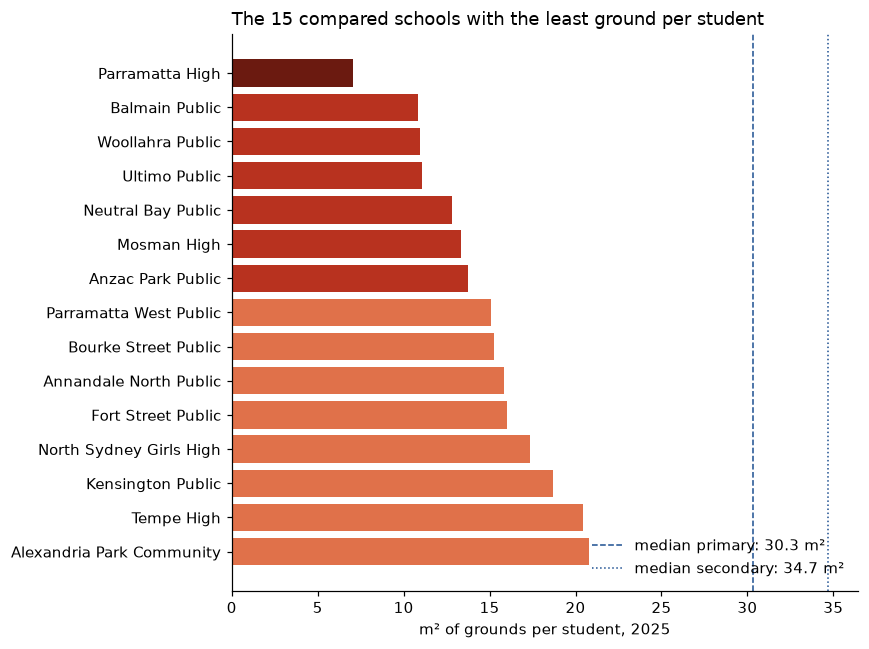

In [6]:
tight = cmp25.sort_values('m2_per_student').head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
colours = [BIN_COLOURS[np.digitize(v, BINS[1:-1])] for v in tight.m2_per_student]
ax.barh(tight.school_name.str.replace(' School', ''), tight.m2_per_student, color=colours)
for lvl, ls in [('Primary School', '--'), ('Secondary School', ':')]:
    ax.axvline(med.loc[lvl, 'median'], color=INK, ls=ls, lw=1, label=f"median {lvl.split()[0].lower()}: {med.loc[lvl, 'median']} m²")
ax.set_xlabel('m² of grounds per student, 2025'); ax.legend(frameon=False, loc='lower right')
ax.set_title('The 15 compared schools with the least ground per student', loc='left')
plt.tight_layout(); plt.show()

## The exception: vertical schools

Two schools are built as towers on small sites: Inner Sydney High School (14 storeys, opened 2020, for up to 1,200
students) and Arthur Phillip High School in Parramatta (rebuilt for 2,000 students, the first high-rise public high
school in NSW), both from School Infrastructure NSW. Their land per student says how they were built, not how much room
their students have, so they are not compared with low-rise schools: `vertical` is true and `compare` is false. They
stay in the data and on the map. Inner Sydney High has its own showcase, which estimates its floor space per student:
https://www.getplotlay.com/showcase/inner-sydney-high/

In [7]:
y25[y25.school_name.isin(schools[schools.vertical].school_name)][['school_name', 'students', 'grounds_m2']].round(0)

,school_name,students,grounds_m2
1605,Inner Sydney High School,1161,5687.0
1607,Arthur Phillip High School,1636,12374.0


## Make it human scale

A standard car space (AS/NZS 2890.1, user class 1A) is 2.4 × 5.4 m, 12.96 m².

median primary: 30.3 m², 2.3 car spaces, a square 5.50 m a side
median secondary: 34.7 m², 2.7 car spaces, a square 5.89 m a side


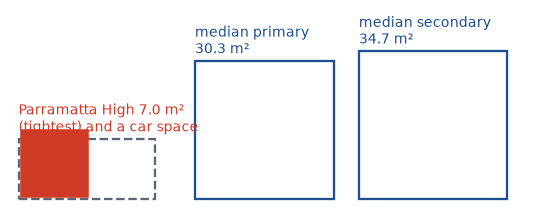

In [8]:
car = 2.4 * 5.4
for lvl in ['Primary School', 'Secondary School']:
    m = med.loc[lvl, 'median']; print(f"median {lvl.split()[0].lower()}: {m} m², {m / car:.1f} car spaces, a square {np.sqrt(m):.2f} m a side")
tight1 = cmp25.sort_values('m2_per_student').iloc[0]; v = tight1.m2_per_student
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.add_patch(Rectangle((0, 0), 5.4, 2.4, fill=False, ls='--', ec=MUTED, lw=1.5))
s = np.sqrt(v); ax.add_patch(Rectangle((0.1, 0.1), s, s, color=RED))
for i, (lvl, x0) in enumerate([('Primary School', 7), ('Secondary School', 7 + np.sqrt(med.loc['Primary School', 'median']) + 1)]):
    m = med.loc[lvl, 'median']; ax.add_patch(Rectangle((x0, 0), np.sqrt(m), np.sqrt(m), fill=False, ec=INK, lw=1.5))
    ax.text(x0, np.sqrt(m) + 0.3, f"median {lvl.split()[0].lower()}\n{m} m²", fontsize=9, color=INK)
ax.text(0, 2.7, f"{tight1.school_name.replace(' School', '')} {v:.1f} m²\n(tightest) and a car space", fontsize=9, color=RED)
ax.set_xlim(-0.3, 20); ax.set_ylim(-0.3, 7.5); ax.set_aspect('equal'); ax.axis('off')
plt.show()

## The map

Coloured by m² of grounds per student in 2025, in the same five bands as the story visuals. Grey: not compared (a
school for specific purposes, an outline that could not be checked, or a vertical school). No basemap: nothing is downloaded.

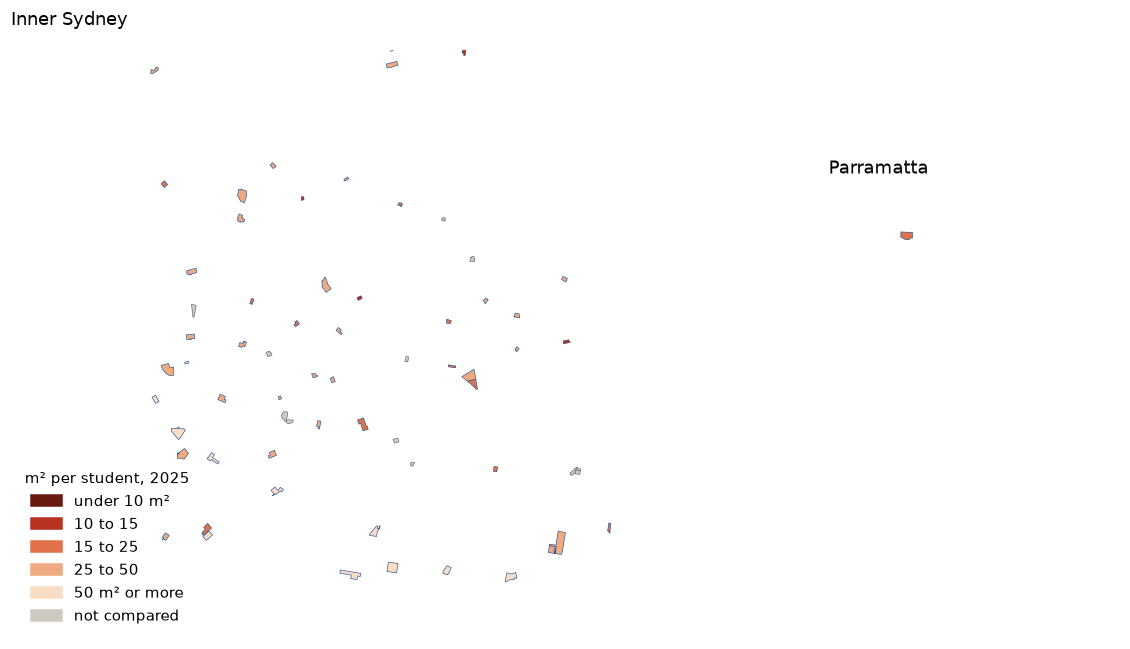

In [9]:
m = g.merge(y25[['school_key', 'm2_per_student']], on='school_key', how='left').to_crs(7856)
m['band'] = pd.cut(m.m2_per_student, BINS, labels=BIN_LABELS, right=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={'width_ratios': [3, 1]})
for ax, box in zip(axes, [(326000, 6243000, 341000, 6255000), (313000, 6252000, 317000, 6256000)]):
    for lab, col in zip(BIN_LABELS, BIN_COLOURS):
        part = m[(m.band == lab) & m['compare']]
        if len(part): part.plot(ax=ax, color=col, edgecolor=INK, lw=0.4)
    m[~m['compare']].plot(ax=ax, color='#cfcac0', edgecolor=MUTED, lw=0.4)
    ax.set_xlim(box[0], box[2]); ax.set_ylim(box[1], box[3]); ax.set_axis_off(); ax.set_aspect('equal')
axes[0].set_title('Inner Sydney', loc='left'); axes[1].set_title('Parramatta', loc='left')
handles = [Rectangle((0, 0), 1, 1, color=c) for c in BIN_COLOURS] + [Rectangle((0, 0), 1, 1, color='#cfcac0')]
axes[0].legend(handles, BIN_LABELS + ['not compared'], loc='lower left', frameon=False, title='m² per student, 2025')
plt.tight_layout(); plt.show()

## New schools open a year group at a time

Headcount for the schools that opened or were rebuilt since 2015. The new schools climb because they open a year group
at a time, a planned staged opening, not a surge in demand (sources in the repository README):

| School | Opened with | All year groups from |
|---|---|---|
| Inner Sydney High | Year 7 (2020) | 2025 (Years 7 to 12) |
| Cammeraygal High | Year 7 (2015) | 2020 (Years 7 to 12) |
| Anzac Park Public | Kindergarten (2016) | 2017 (K to 6) |
| Bayanami Public | Kindergarten (2019) | 2020 (K to 6) |
| Green Square Public | Kindergarten to Year 2 (2025) | 2027 (K to 6) |

Arthur Phillip High and Alexandria Park Community School are existing schools with new buildings.

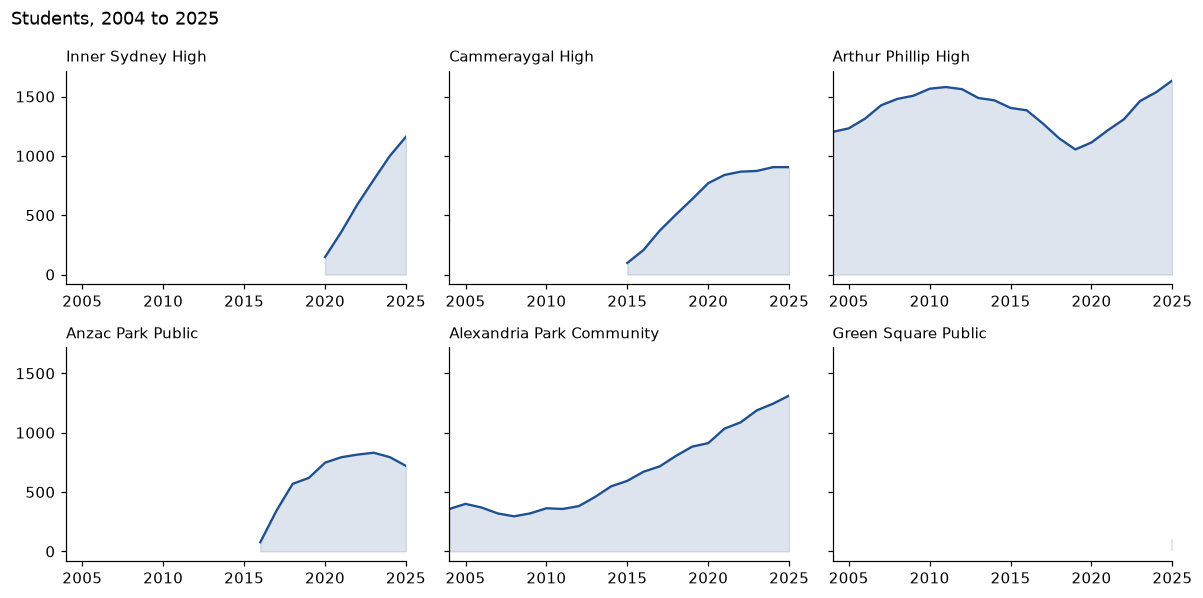

In [10]:
picks = ['Inner Sydney High School', 'Cammeraygal High School', 'Arthur Phillip High School', 'Anzac Park Public School', 'Alexandria Park Community School', 'Green Square Public School']
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharey=True)
for ax, n in zip(axes.flat, picks):
    s = long[long.school_name == n]
    ax.fill_between(s.year, s.students, color=INK, alpha=.15); ax.plot(s.year, s.students, color=INK)
    ax.set_title(n.replace(' School', ''), loc='left', fontsize=10); ax.set_xlim(2004, 2025)
fig.suptitle('Students, 2004 to 2025', x=0.01, ha='left'); plt.tight_layout(); plt.show()

## Primary down, high school up

Primary and high school totals in the study area. Part of the high school rise is Inner Sydney High and Cammeraygal High
still adding year groups after 2019, so the totals are also shown without them. Randwick High is a 2025 merger of Randwick Boys and Randwick Girls
High; their earlier headcounts are in `randwick_before_merger` so the high school line is like for like.

Primary School: 24,389 (2019) to 20,641 (2025), -15.4%
Secondary School: 17,035 (2019) to 19,242 (2025), +13.0%
Primary School without Bayanami Public, Green Square Public: -18.3%
Secondary School without Inner Sydney High, Cammeraygal High: +4.7%


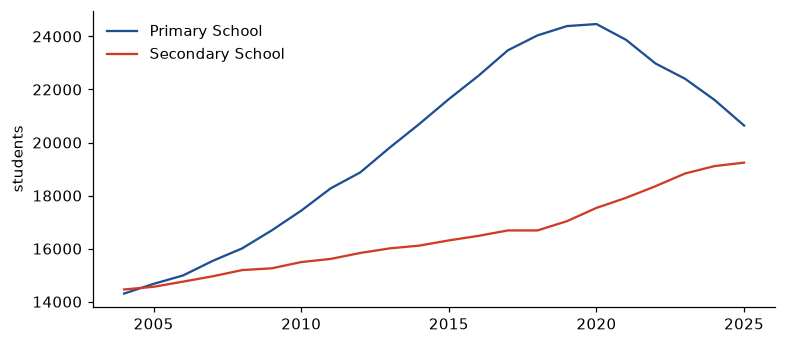

In [11]:
lvl = long[long.level.isin(['Primary School', 'Secondary School'])].groupby(['year', 'level']).students.sum().unstack()
pre = pd.read_csv(f'{DATA}/schools/randwick_before_merger.csv').set_index('year').students
lvl['Secondary School'] = lvl['Secondary School'].add(pre, fill_value=0)
for k in lvl: print(f"{k}: {lvl.loc[2019, k]:,.0f} (2019) to {lvl.loc[2025, k]:,.0f} (2025), {lvl.loc[2025, k] / lvl.loc[2019, k] - 1:+.1%}")
# without the schools still adding year groups after 2019
still = {'Primary School': ['Bayanami Public School', 'Green Square Public School'], 'Secondary School': ['Inner Sydney High School', 'Cammeraygal High School']}
for k, names in still.items():
    x = lvl[k] - long[long.school_name.isin(names)].groupby('year').students.sum().reindex(lvl.index, fill_value=0)
    print(f"{k} without {', '.join(n.replace(' School', '') for n in names)}: {x.loc[2025] / x.loc[2019] - 1:+.1%}")
ax = lvl.plot(figsize=(8, 3.5), color=[INK, RED]); ax.set_xlabel(''); ax.set_ylabel('students'); ax.legend(frameon=False)
plt.show()

## Attendance

Semester 1 attendance. There is no 2020 data, and the department says 2021 is not comparable with other years.

In [12]:
a = att.pivot_table(index='school_key', columns='year', values='attendance_pct')
print('mean attendance:', a.mean().round(1).loc[[2019, 2022, 2024]].to_dict())
both = a[[2019, 2024]].dropna()
print(f'{(both[2024] < both[2019]).sum()} of {len(both)} schools were below their 2019 attendance in 2024')
r = cmp25.merge(a[2024].rename('att_2024'), left_on='school_key', right_index=True).dropna(subset=['att_2024'])
print(f"Spearman correlation of ground per student and 2024 attendance: {r[['m2_per_student', 'att_2024']].corr('spearman').iloc[0, 1]:.2f} ({len(r)} schools): no clear link")

mean attendance: {2019: 93.7, 2022: 88.0, 2024: 90.3}
68 of 72 schools were below their 2019 attendance in 2024
Spearman correlation of ground per student and 2024 attendance: -0.33 (64 schools): no clear link


## Caveats

- Grounds are land, buildings included: not floor space, not playground area. Parks next door are not counted.
- Areas are as picked or drawn and are approximate. Accuracy depends on the cadastre and the imagery.
- Headcount, not capacity: the open data has no capacity figures, so nothing here says a school is over capacity.
- Suppressed headcounts stay blank.
- Grounds per student and attendance are shown side by side; no cause is claimed.
- The two vertical schools are in the data and on the map, but not compared on land.

## Checks

If a shape changes, these catch it.

In [13]:
assert len(cmp25) == 66, len(cmp25)
assert 29.5 <= med.loc['Primary School', 'median'] <= 31 and 33.5 <= med.loc['Secondary School', 'median'] <= 36, med
assert sorted(schools[schools.vertical].school_name) == ['Arthur Phillip High School', 'Inner Sydney High School']
assert not schools[schools.vertical]['compare'].any()
assert g.geometry.notna().all() and len(g) == 81
out = y25[['school_key', 'school_name', 'level', 'students', 'grounds_m2', 'm2_per_student', 'compare']].round(1)
print('all checks passed;', len(out), 'schools in the 2025 table')

all checks passed; 81 schools in the 2025 table
